# How Has Netflix's Catalogue Changed? (2015–2020)

**Question:** How did the mix of Netflix content (movies vs TV shows, countries, audience ratings, genres) change as the catalogue grew?

**Data:** Kaggle *Netflix Movies and TV Shows* dataset, 8,807 titles. It is a snapshot that ends in **September 2021**, so 2021 is only a partial year.

**Tools:** Python, pandas, matplotlib

**Notebook structure**
1. Load and inspect the data
2. Clean the data (every fix is explained)
3. Analysis (one question per section)
4. Key findings and limitations

## 1. Load and inspect the data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3})

df = pd.read_csv("netflix_titles.csv")
print(df.shape)
df.head()

(8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
# Missing values (%) and duplicates
missing = (df.isnull().sum() / len(df) * 100).round(2)
print(missing[missing > 0].sort_values(ascending=False))
print("\nDuplicate rows:", df.duplicated().sum())

director      29.91
country        9.44
cast           9.37
date_added     0.11
rating         0.05
duration       0.03
dtype: float64

Duplicate rows: 0


## 2. Data cleaning

| Problem found | Fix |
|---|---|
| 3 rows have a runtime (e.g. "74 min") in the `rating` column | Move it to `duration`, set `rating` to missing |
| `director`, `cast`, `country` have missing values | Fill with one consistent label: "Unknown" (excluded from country analysis later) |
| `date_added` is text, some values have leading spaces | Strip spaces, convert to datetime |
| `duration` mixes minutes (movies) and seasons (TV shows) | Split into `movie_minutes` and `tv_seasons` |
| `country` and `listed_in` hold several values in one cell | Split and `explode()` at analysis time so every value counts |

In [4]:
# One cleaned copy, all cleaning in this section
df_clean = df.copy()

# 1) Runtimes that ended up in the rating column
bad_rating = df_clean["rating"].str.contains("min", na=False)
print(df_clean.loc[bad_rating, ["title", "rating", "duration"]])
df_clean.loc[bad_rating, "duration"] = df_clean.loc[bad_rating, "rating"]
df_clean.loc[bad_rating, "rating"] = np.nan

# 2) Missing text columns -> one consistent label
for col in ["director", "cast", "country"]:
    df_clean[col] = df_clean[col].fillna("Unknown")

                                     title  rating duration
5541                       Louis C.K. 2017  74 min      NaN
5794                 Louis C.K.: Hilarious  84 min      NaN
5813  Louis C.K.: Live at the Comedy Store  66 min      NaN


In [5]:
# 3) Dates
df_clean["date_added"] = pd.to_datetime(df_clean["date_added"].str.strip(), format="mixed", errors="coerce")
df_clean["year_added"] = df_clean["date_added"].dt.year
df_clean["release_decade"] = (df_clean["release_year"] // 10) * 10

# 4) Duration -> numbers (minutes for movies, seasons for TV shows)
duration_num = df_clean["duration"].str.extract(r"(\d+)")[0].astype(float)
df_clean["movie_minutes"] = duration_num.where(df_clean["type"] == "Movie")
df_clean["tv_seasons"] = duration_num.where(df_clean["type"] == "TV Show")

# 5) Group ratings into audience levels
audience_map = {
    "TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
    "TV-PG": "Family", "PG": "Family",
    "TV-14": "Teens", "PG-13": "Teens",
    "TV-MA": "Adults", "R": "Adults", "NC-17": "Adults",
}
df_clean["audience"] = df_clean["rating"].map(audience_map).fillna("Unrated/Other")

print("Latest date in data:", df_clean["date_added"].max().date())
df_clean.isnull().sum()

Latest date in data: 2021-09-25


show_id              0
type                 0
title                0
director             0
cast                 0
country              0
date_added          10
release_year         0
rating               7
duration             0
listed_in            0
description          0
year_added          10
release_decade       0
movie_minutes     2676
tv_seasons        6131
audience             0
dtype: int64

## 3. Analysis

### 3.1 What is the overall catalogue mix: movies or TV shows?

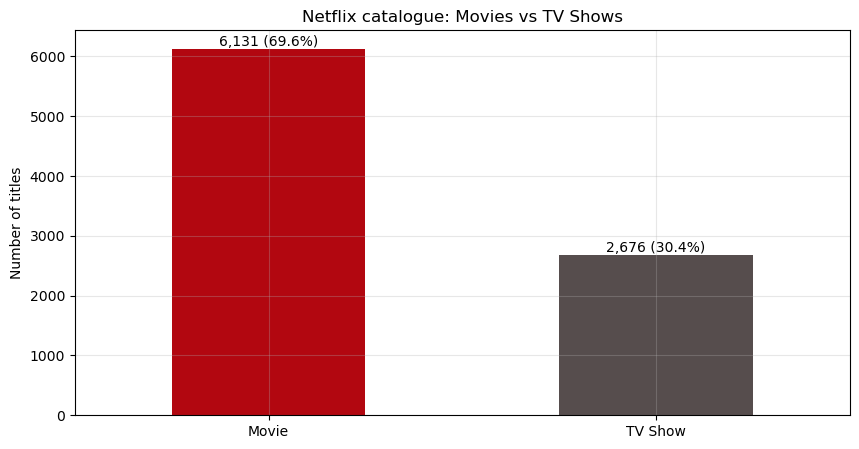

In [6]:
counts = df_clean["type"].value_counts()
share = (counts / counts.sum() * 100).round(1)

ax = counts.plot(kind="bar", color=["#b20710", "#564d4d"], rot=0)
ax.set_title("Netflix catalogue: Movies vs TV Shows")
ax.set_xlabel("")
ax.set_ylabel("Number of titles")
for i, (c, s) in enumerate(zip(counts, share)):
    ax.text(i, c, f"{c:,} ({s}%)", ha="center", va="bottom")
plt.show()

Movies make up about **70%** of the catalogue (6,131 titles) and TV shows about **30%** (2,676 titles).

### 3.2 How fast did the catalogue grow, and did the mix shift?
2021 is excluded here because the data stops in September 2021 (partial year). Before 2015 there are too few titles to compare.

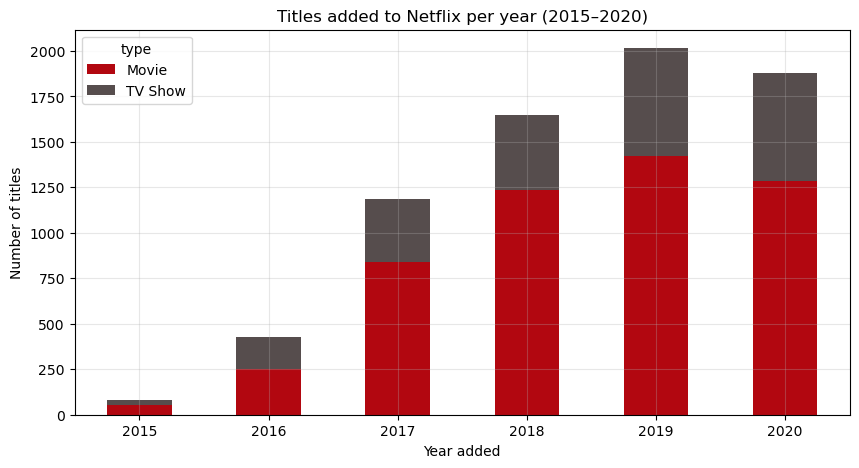

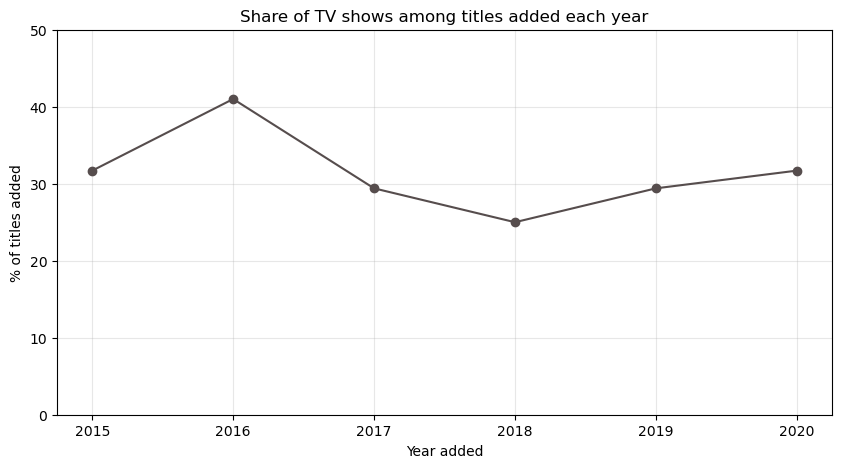

In [7]:
full_years = df_clean[df_clean["year_added"].between(2015, 2020)]
yearly = full_years.groupby(["year_added", "type"]).size().unstack(fill_value=0)
yearly.index = yearly.index.astype(int)

ax = yearly.plot(kind="bar", stacked=True, color=["#b20710", "#564d4d"], rot=0)
ax.set_title("Titles added to Netflix per year (2015–2020)")
ax.set_xlabel("Year added")
ax.set_ylabel("Number of titles")
plt.show()

tv_share = (yearly["TV Show"] / yearly.sum(axis=1) * 100).round(1)
ax = tv_share.plot(marker="o", color="#564d4d")
ax.set_title("Share of TV shows among titles added each year")
ax.set_xlabel("Year added")
ax.set_ylabel("% of titles added")
ax.set_ylim(0, 50)
plt.show()

- Yearly additions grew from about **80 titles in 2015 to roughly 2,000 in 2019**, then dipped to about 1,880 in 2020.
- TV show additions grew every year through 2020 (26 → 595), while movie additions peaked in 2019.
- The TV share dipped to about **25% in 2018** and has risen since (29% in 2019, 32% in 2020).

### 3.3 Which countries produce the content?
`country` can list several countries per title (e.g. "United States, India"), so each country is counted once for every title it appears in. Titles with no country are excluded.

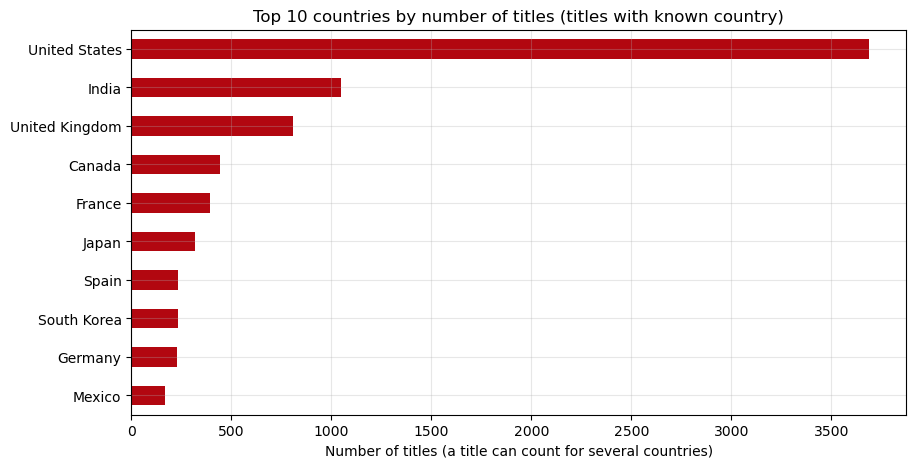

Share of titles with known country that involve each country (%):
country
United States     46.3
India             13.1
United Kingdom    10.1
Canada             5.6
France             4.9
Japan              4.0
Spain              2.9
South Korea        2.9
Germany            2.8
Mexico             2.1
Name: count, dtype: float64


In [8]:
known = df_clean[df_clean["country"] != "Unknown"]
countries = known["country"].str.split(",").explode().str.strip()
countries = countries[countries != ""]

top_countries = countries.value_counts().head(10)
pct = (top_countries / len(known) * 100).round(1)

ax = top_countries.sort_values().plot(kind="barh", color="#b20710")
ax.set_title("Top 10 countries by number of titles (titles with known country)")
ax.set_xlabel("Number of titles (a title can count for several countries)")
ax.set_ylabel("")
plt.show()
print("Share of titles with known country that involve each country (%):")
print(pct)


The United States dominates the Netflix catalogue, appearing in 46.3% of titles with a known country. This is a substantial lead of 33.2 percentage points over India (13.1%) and 36.2 percentage points over the United Kingdom (10.1%). The gap between India and the UK is much smaller at just 3 percentage points, highlighting how strongly the US leads the catalogue

### 3.4 Who is the content for? (audience ratings over time)
Ratings are grouped into Kids, Family, Teens and Adults (see the mapping in the cleaning section).

Overall audience mix (%):
audience
Kids             10.3
Family           13.1
Teens            30.1
Adults           45.5
Unrated/Other     1.0
Name: proportion, dtype: float64


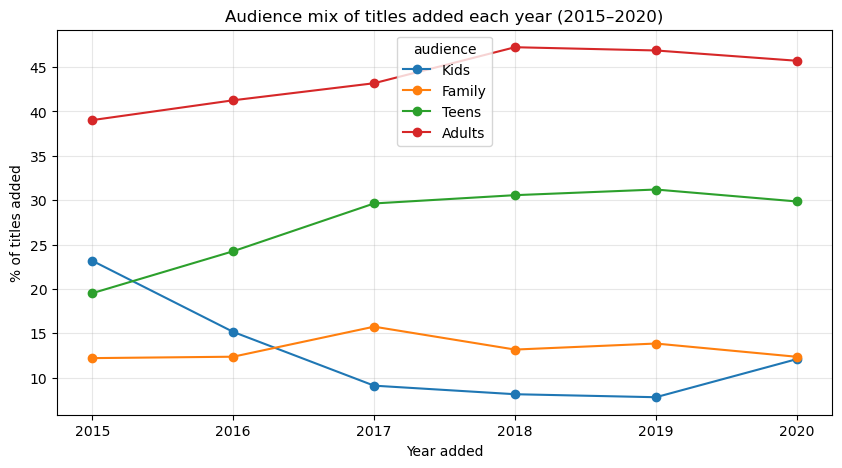

In [9]:
full_years = df_clean[df_clean["year_added"].between(2015, 2020)]   # re-select so the audience column is included
order = ["Kids", "Family", "Teens", "Adults", "Unrated/Other"]

overall = df_clean["audience"].value_counts(normalize=True).reindex(order).fillna(0).mul(100).round(1)
print("Overall audience mix (%):")
print(overall)

by_year = full_years.groupby(["year_added", "audience"]).size().unstack(fill_value=0).reindex(columns=order, fill_value=0)
by_year.index = by_year.index.astype(int)
by_year_pct = by_year.div(by_year.sum(axis=1), axis=0) * 100

ax = by_year_pct[["Kids", "Family", "Teens", "Adults"]].plot(marker="o")
ax.set_title("Audience mix of titles added each year (2015–2020)")
ax.set_xlabel("Year added")
ax.set_ylabel("% of titles added")
plt.show()

Adults represent the largest audience category, accounting for 45.5% of titles. Their share generally increased between 2015 and 2019, followed by a slight decline in 2020. Teen-oriented content also experienced notable growth, while the share of kids' content declined overall.

### 3.5 Which genres are most common?
Each title can have up to three genres, so every genre is counted (not just the first one).

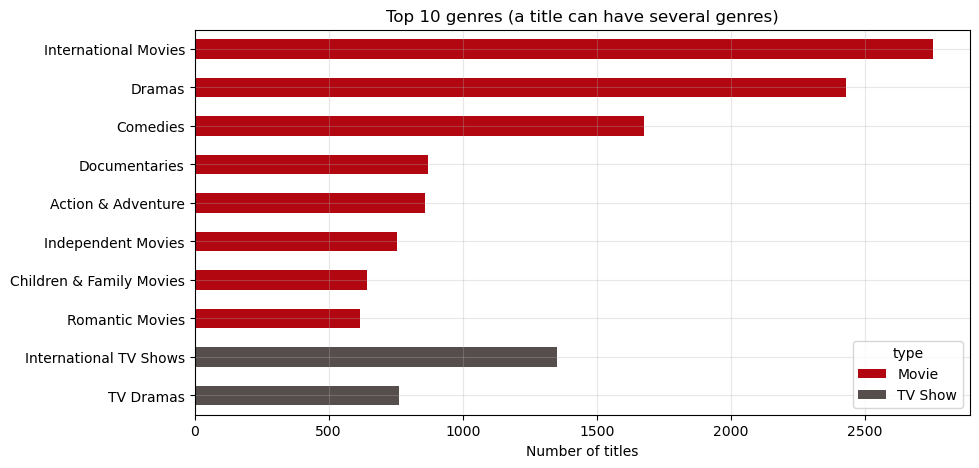

In [10]:
genres = (
    df_clean[["type", "listed_in"]]
    .assign(genre=df_clean["listed_in"].str.split(","))
    .explode("genre")
)
genres["genre"] = genres["genre"].str.strip()

genre_table = genres.groupby(["genre", "type"]).size().unstack(fill_value=0)
top10 = genre_table.sum(axis=1).nlargest(10).index
ax = genre_table.loc[top10].sort_values(by=list(genre_table.columns), ascending=True).plot(
    kind="barh", stacked=True, color=["#b20710", "#564d4d"]
)
ax.set_title("Top 10 genres (a title can have several genres)")
ax.set_xlabel("Number of titles")
ax.set_ylabel("")
plt.show()

The three most prominent categories are International Movies, Dramas and Comedies. International Movies lead the overall distribution, highlighting the significant presence of internationally categorised content in Netflix's catalogue.

This connects with the country analysis, where the United States accounts for the largest share of titles, followed by India and the United Kingdom. Despite the US dominance, the catalogue includes contributions from several countries, reflecting Netflix's broad international content mix.

Interestingly, the presence of International Movies and International TV Shows suggests that Netflix's catalogue is not limited to productions from a single country or market.

### 3.6 How long are movies, and how many seasons do TV shows have?

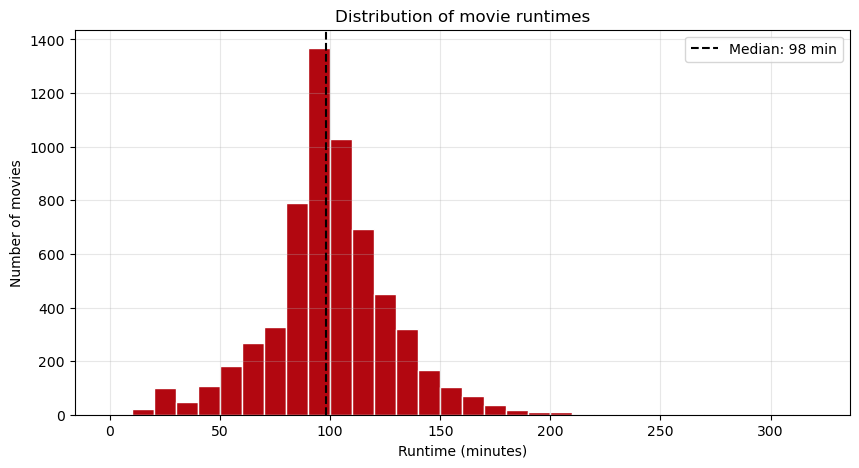

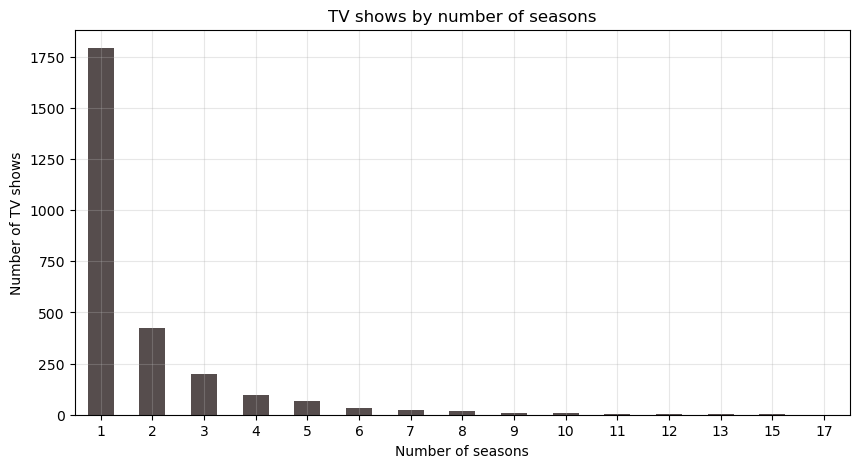

In [11]:
minutes = df_clean["movie_minutes"].dropna()
median_min = minutes.median()

plt.hist(minutes, bins=range(0, int(minutes.max()) + 10, 10), color="#b20710", edgecolor="white")
plt.axvline(median_min, color="black", linestyle="--", label=f"Median: {median_min:.0f} min")
plt.title("Distribution of movie runtimes")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Number of movies")
plt.legend()
plt.show()

seasons = df_clean["tv_seasons"].dropna().astype(int).value_counts().sort_index()
ax = seasons.plot(kind="bar", color="#564d4d", rot=0)
ax.set_title("TV shows by number of seasons")
ax.set_xlabel("Number of seasons")
ax.set_ylabel("Number of TV shows")
plt.show()

- The median movie runtime is **98 minutes**, and most movies fall between 80 and 110 minutes.
- Most TV shows have **1 season**, and the count drops quickly for longer series.

## 4. Key numbers for the conclusion

In [12]:
us_pct = pct.iloc[0]
print(f"Top country: {pct.index[0]} ({us_pct}% of titles with known country)")
print(f"Top genre: {genre_table.sum(axis=1).idxmax()} ({genre_table.sum(axis=1).max():,} titles)")
print(f"TV share of additions: {tv_share.loc[2015]}% (2015) -> {tv_share.loc[2020]}% (2020)")
print(f"Adults share of additions: {by_year_pct.loc[2015, 'Adults']:.1f}% (2015) -> {by_year_pct.loc[2020, 'Adults']:.1f}% (2020)")
print(f"Median movie runtime: {median_min:.0f} min")

Top country: United States (46.3% of titles with known country)
Top genre: International Movies (2,752 titles)
TV share of additions: 31.7% (2015) -> 31.7% (2020)
Adults share of additions: 39.0% (2015) -> 45.7% (2020)
Median movie runtime: 98 min


## Key Findings

1. **Catalogue composition:** Netflix's catalogue consists of approximately 70% movies and 30% TV shows.
2. **Content additions:** Yearly catalogue additions increased significantly between 2015 and 2019, reaching their peak around 2019.
3. **Country distribution:** The United States leads the catalogue, accounting for 46.3% of titles with known country information. India and the United Kingdom follow with 13.1% and 10.1%, respectively.
4. **Audience categories:** Adult-oriented titles represent the largest audience category at 45.5%. Their share increased from 39.0% in 2015 to 45.7% in 2020.
5. **Genre distribution:** International Movies is the most frequent genre category, with 2,752 titles, followed by Dramas and Comedies.
6. **Movie runtimes:** The median movie runtime is 98 minutes, with most movies concentrated around the 80–110-minute range.
7. **TV show seasons:** TV shows with one season dominate the catalogue, while long-running series with seven or more seasons are relatively uncommon.

**Limitations**
- The data is a snapshot ending in September 2021, so the 2021 numbers are partial and nothing after that is covered.
- `date_added` is when a title joined Netflix, not when it was released.
- This describes the catalogue (what is available), not viewership (what people watch).
- About 9% of titles have no country, so the country results only cover titles with known countries.
- Titles with several countries or genres are counted once per country or genre, so those totals add up to more than the number of titles.